# TRSP Thesis Figures
Generates all figures for the TRSP Results section of the thesis.
Outputs are saved to `results/figures/`.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# serif fonts to match LaTeX output
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
})

BASE = Path('..').resolve()
RUNS = BASE / 'runs' / 'trsp'
FIG_DIR = BASE / 'results' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Base:', BASE)
print('Figures will be saved to:', FIG_DIR)

Base: /home/shinobi-owl/PhD/battery/DroneSim
Figures will be saved to: /home/shinobi-owl/PhD/battery/DroneSim/results/figures


## Config: policy IDs for K=1 training curves

In [2]:
# Policy IDs for K=1 (static traffic) — used for training convergence plots
TRAIN_K1 = {
    'SARSA': {'grid': 'ff58b1a9', 'rand_grid': 'c028b992', 'ames': '6323f08f'},
    'DQN':   {'grid': '5b6c4910', 'rand_grid': '9a9355f4', 'ames': 'a4f68fc2'},
    'A2C':   {'grid': '6ca77d6d', 'rand_grid': '6612942d', 'ames': '85cd4c78'},
    'PPO':   {'grid': '5dd13f39', 'rand_grid': '10b2e74c', 'ames': '342d1614'},
}

NET_COLORS = {'grid': '#1f77b4', 'rand_grid': '#ff7f0e', 'ames': '#2ca02c'}
NET_LABELS = {'grid': 'Grid', 'rand_grid': 'Rand-Grid', 'ames': 'Ames'}
NET_ORDER  = ['grid', 'rand_grid', 'ames']

ALGO_ORDER  = ['SSP', 'SARSA', 'DQN', 'PPO', 'A2C']
ALGO_STYLES = {
    'SSP':   ('-',  'o', '#4c72b0'),
    'SARSA': ('-',  's', '#dd8452'),
    'DQN':   ('-',  '^', '#55a868'),
    'PPO':   ('--', 'D', '#c44e52'),
    'A2C':   ('--', 'v', '#8172b3'),
}
BAR_COLORS = ['#4c72b0', '#dd8452', '#55a868']  # one per network

## Figure 1 — Training Convergence Curves

In [3]:
def load_train_log(policy_id):
    path = RUNS / policy_id / 'train_log.csv'
    if not path.exists():
        print(f'  [skip] no train_log for {policy_id}')
        return None
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    return df

def smooth(y, window):
    return pd.Series(y).rolling(window, min_periods=1).mean().values

# Load all K=1 logs
train_data = {}
for algo, nets in TRAIN_K1.items():
    train_data[algo] = {}
    for net, pid in nets.items():
        df = load_train_log(pid)
        train_data[algo][net] = df

  [skip] no train_log for a4f68fc2
  [skip] no train_log for 5dd13f39


Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/training_curves.png


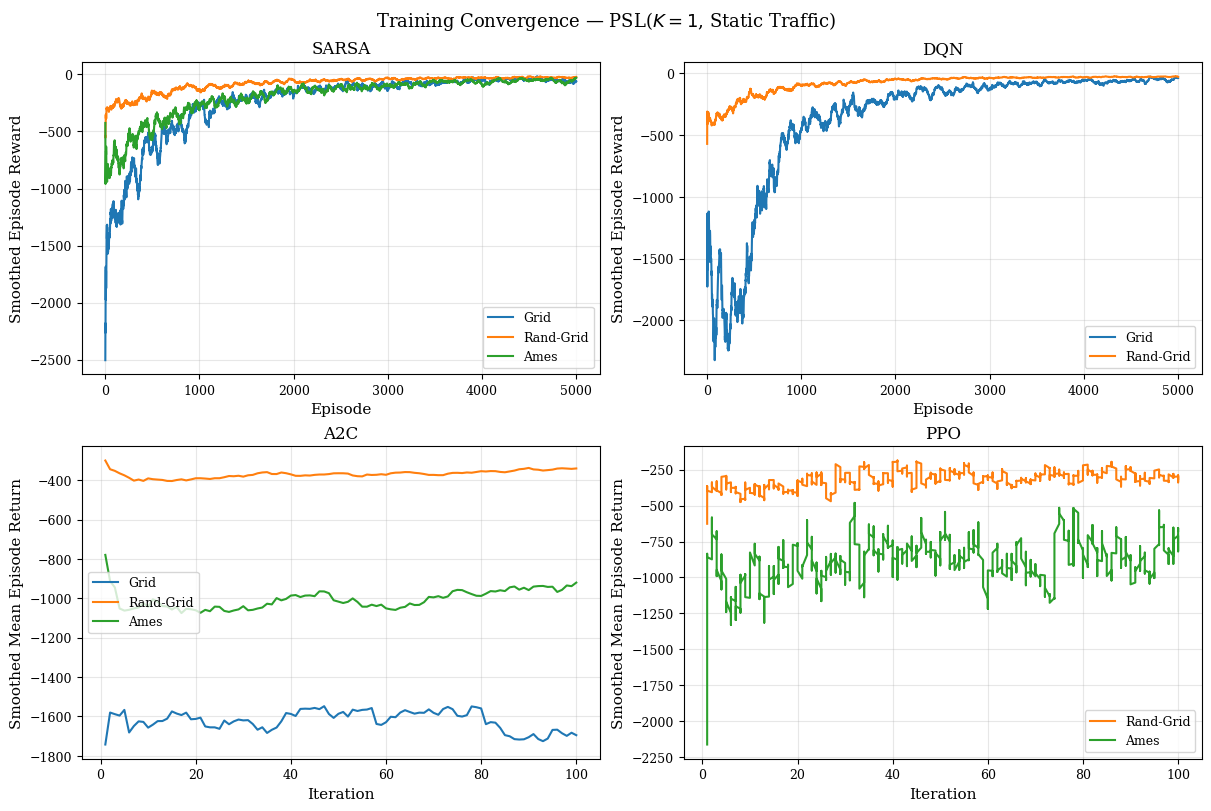

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
fig.suptitle('Training Convergence — PSL($K=1$, Static Traffic)', fontsize=13)

algo_ax = {'SARSA': axes[0, 0], 'DQN': axes[0, 1], 'A2C': axes[1, 0], 'PPO': axes[1, 1]}
SMOOTH_EP   = 50   # episode-based algos (SARSA, DQN)
SMOOTH_ITER = 20   # iteration-based algos (A2C, PPO)

def get_reward_col(df):
    """Return the reward column name regardless of algo log format."""
    for c in ['Total Reward', 'Mean Episode Return', 'Episode Reward']:
        if c in df.columns:
            return c
    # fallback: last numeric column
    return df.select_dtypes('number').columns[-1]

xlabel, ylabel = 'Episode', 'Smoothed Reward'  # defaults (overwritten per algo)

for algo, ax in algo_ax.items():
    for net in NET_ORDER:
        df = train_data[algo].get(net)
        if df is None:
            continue
        color = NET_COLORS[net]
        label = NET_LABELS[net]
        if 'Episode' in df.columns:           # SARSA / DQN
            x      = df['Episode'].values
            y      = smooth(df['Total Reward'].values, SMOOTH_EP)
            xlabel = 'Episode'
            ylabel = 'Smoothed Episode Reward'
        else:                                  # A2C / PPO (Iteration-based)
            x      = df['Iteration'].values
            rcol   = get_reward_col(df)
            y      = smooth(df[rcol].values, SMOOTH_ITER)
            xlabel = 'Iteration'
            ylabel = 'Smoothed Mean Episode Return'
        ax.plot(x, y, color=color, label=label, linewidth=1.5)
    ax.set_title(algo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True, alpha=0.3)

out = FIG_DIR / 'training_curves.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

## Load Test Results

In [5]:
df_test = pd.read_csv(BASE / 'results' / 'trsp_results.csv')

net_map     = {'N1': 'grid', 'N2': 'rand_grid', 'N3': 'ames'}
traffic_map = {'T1': 1, 'T2': 2, 'T3': 3, 'T4': 4}

df_test['network_name'] = df_test['network'].map(net_map)
df_test['K']            = df_test['traffic'].map(traffic_map)
df_test['algo_label']   = df_test['algo'].str.upper().replace({'DIJKSTRA': 'SSP'})
df_test['success_pct']  = df_test['success_rate'] * 100

NET_DISPLAY = {'grid': 'Grid', 'rand_grid': 'Rand-Grid', 'ames': 'Ames'}

print(df_test[['network_name', 'K', 'algo_label', 'makespan_mean', 'success_pct']].to_string())

   network_name  K algo_label  makespan_mean  success_pct
0          grid  1        DQN         181.56         98.0
1          grid  1        PPO         147.30         10.0
2          grid  1        A2C         130.08         12.0
3          grid  1        SSP         214.04         98.0
4          grid  1      SARSA         182.88         98.0
5          grid  2      SARSA         198.61         98.0
6          grid  2        PPO         146.29         14.0
7          grid  2        DQN         195.10         98.0
8          grid  2        SSP         229.12         97.0
9          grid  2        A2C         131.18         17.0
10         grid  3        PPO         102.60         15.0
11         grid  3        A2C         155.54         26.0
12         grid  3      SARSA         201.02         97.0
13         grid  3        SSP         200.92         98.0
14         grid  3        DQN         191.21         98.0
15         grid  4        A2C         147.59         29.0
16         gri

## Figure 2 — Makespan & Success Rate for K=1

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/makespan_k1.png


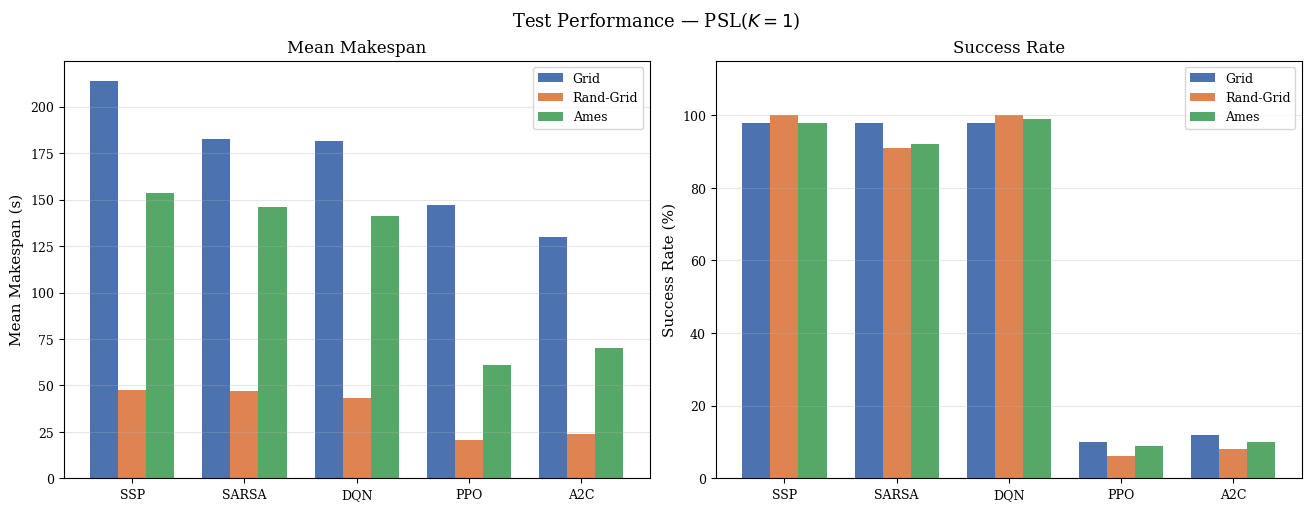

In [6]:
df_k1 = df_test[df_test['K'] == 1].copy()

x     = np.arange(len(ALGO_ORDER))
width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
fig.suptitle('Test Performance — PSL($K=1$)', fontsize=13)

# ---- Makespan ----
ax = axes[0]
for i, net in enumerate(NET_ORDER):
    vals = []
    for algo in ALGO_ORDER:
        row = df_k1[(df_k1['network_name'] == net) & (df_k1['algo_label'] == algo)]
        vals.append(row['makespan_mean'].values[0] if len(row) > 0 else 0.0)
    ax.bar(x + i * width, vals, width, label=NET_DISPLAY[net], color=BAR_COLORS[i])
ax.set_xticks(x + width)
ax.set_xticklabels(ALGO_ORDER)
ax.set_ylabel('Mean Makespan (s)')
ax.set_title('Mean Makespan')
ax.legend()
ax.grid(True, axis='y', alpha=0.3)

# ---- Success Rate ----
ax = axes[1]
for i, net in enumerate(NET_ORDER):
    vals = []
    for algo in ALGO_ORDER:
        row = df_k1[(df_k1['network_name'] == net) & (df_k1['algo_label'] == algo)]
        vals.append(row['success_pct'].values[0] if len(row) > 0 else 0.0)
    ax.bar(x + i * width, vals, width, label=NET_DISPLAY[net], color=BAR_COLORS[i])
ax.set_xticks(x + width)
ax.set_xticklabels(ALGO_ORDER)
ax.set_ylabel('Success Rate (%)')
ax.set_title('Success Rate')
ax.set_ylim(0, 115)
ax.legend()
ax.grid(True, axis='y', alpha=0.3)

out = FIG_DIR / 'makespan_k1.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

## Figure 3 — Effect of K on Makespan

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/effect_of_k.png


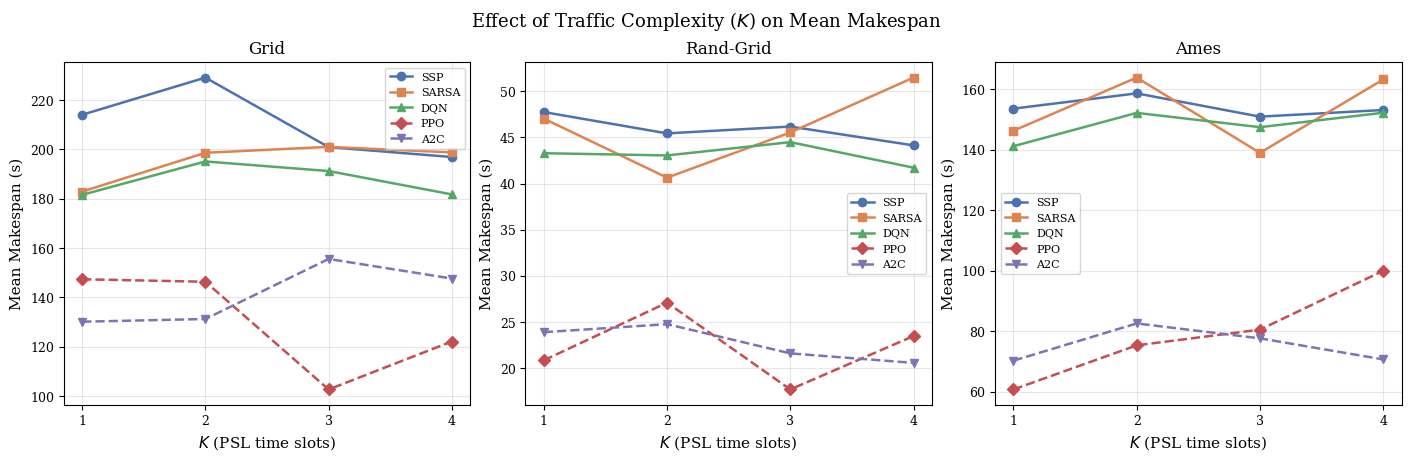

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)
fig.suptitle('Effect of Traffic Complexity ($K$) on Mean Makespan', fontsize=13)

for ax, net in zip(axes, NET_ORDER):
    for algo, (ls, marker, color) in ALGO_STYLES.items():
        Ks, means = [], []
        for k in [1, 2, 3, 4]:
            row = df_test[(df_test['network_name'] == net) &
                          (df_test['K'] == k) &
                          (df_test['algo_label'] == algo)]
            if len(row) > 0:
                Ks.append(k)
                means.append(row['makespan_mean'].values[0])
        ax.plot(Ks, means, linestyle=ls, marker=marker, color=color,
                label=algo, linewidth=1.8, markersize=6)
    ax.set_title(NET_DISPLAY[net])
    ax.set_xlabel('$K$ (PSL time slots)')
    ax.set_ylabel('Mean Makespan (s)')
    ax.set_xticks([1, 2, 3, 4])
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

out = FIG_DIR / 'effect_of_k.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

## Figure 4 — Success Rate vs K

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/success_rate.png


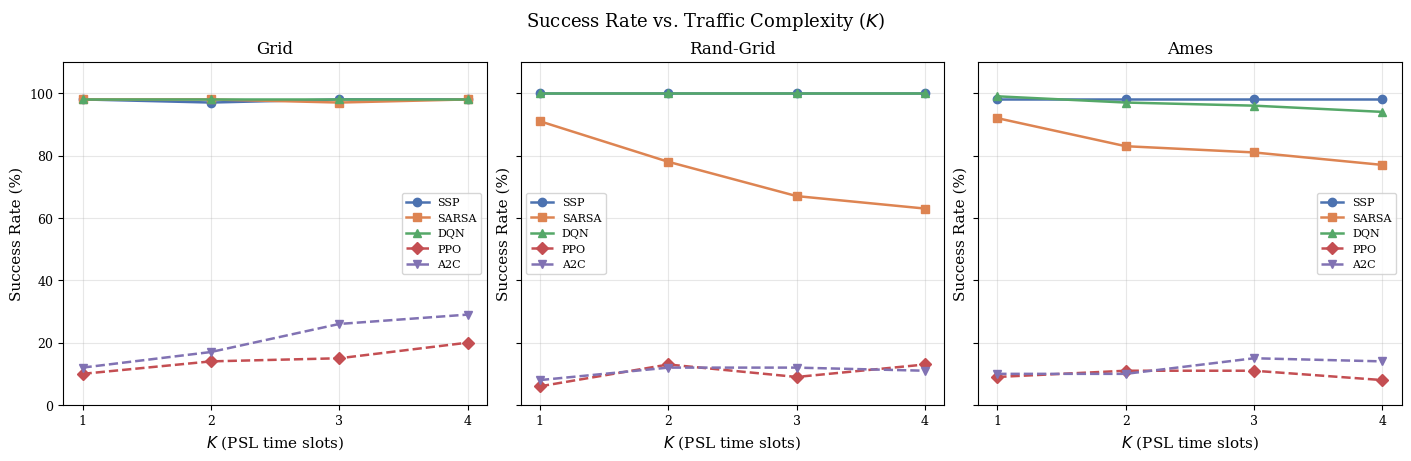

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True, sharey=True)
fig.suptitle('Success Rate vs. Traffic Complexity ($K$)', fontsize=13)

for ax, net in zip(axes, NET_ORDER):
    for algo, (ls, marker, color) in ALGO_STYLES.items():
        Ks, srs = [], []
        for k in [1, 2, 3, 4]:
            row = df_test[(df_test['network_name'] == net) &
                          (df_test['K'] == k) &
                          (df_test['algo_label'] == algo)]
            if len(row) > 0:
                Ks.append(k)
                srs.append(row['success_pct'].values[0])
        ax.plot(Ks, srs, linestyle=ls, marker=marker, color=color,
                label=algo, linewidth=1.8, markersize=6)
    ax.set_title(NET_DISPLAY[net])
    ax.set_xlabel('$K$ (PSL time slots)')
    ax.set_ylabel('Success Rate (%)')
    ax.set_xticks([1, 2, 3, 4])
    ax.set_ylim(0, 110)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

out = FIG_DIR / 'success_rate.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()